# Day 3 - Exploring Mumbai Rental Profiles
Group 3: Ahmed Belahcen, Nandini Rathod, Sanjana Kiran, Akanksha Dhumal.
AI Methods I, IAAC MaAI 2026/27.



### Load the existing cleaned snapshot
One row is an advertised property listing. It may not represent a unique dwelling. This CSV is reused from Day 2 without changing it. Inspecting data does not mean the data is already suitable for clustering.



In [10]:
from pathlib import Path
import pandas as pd

# Support running from notebook/ or the project root in VS Code.
project_dir = Path.cwd()
if not (project_dir / "data/mumbai_cleaned.csv").exists():
    project_dir = project_dir.parent

data_path = project_dir / "data/mumbai_cleaned.csv"
df = pd.read_csv(data_path)
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (18846, 26)


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,...,Description,Property Image,Price_per_m2,Suspicious_Price,Price_num,Area_num,BHK_num,Bathrooms_num,Balconies_num,Furnished_clean
0,1BHK Multistorey Apartment for Rent in Bandra ...,70000.0,750.0,1.0,1.0,Furnished,NaN,7.0,Unknown,South -West,...,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg,93.333333,False,70000.0,750.0,1.0,1.0,NaN,Furnished
1,3BHK Multistorey Apartment for Rent in Lodha N...,140000.0,1980.0,3.0,4.0,Unfurnished,4.0,21.0,Unknown,East,...,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg,70.707071,False,140000.0,1980.0,3.0,4.0,4.0,Unfurnished
2,3BHK Multistorey Apartment for Rent in Lodha P...,190000.0,1592.0,3.0,3.0,Unfurnished,1.0,20.0,Unknown,North - East,...,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg,119.346734,False,190000.0,1592.0,3.0,3.0,1.0,Unfurnished
3,3BHK Multistorey Apartment for Rent in Rustomj...,110000.0,1305.0,3.0,3.0,Unfurnished,3.0,11.0,Freehold,West,...,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg,84.291188,False,110000.0,1305.0,3.0,3.0,3.0,Unfurnished
4,3BHK Multistorey Apartment for Rent in DLH The...,140000.0,1350.0,3.0,3.0,Unfurnished,NaN,29.0,Freehold,East,...,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg,103.703704,False,140000.0,1350.0,3.0,3.0,NaN,Unfurnished


### What information is available?

We look at names and data types before selecting any feature. Several `_num` columns duplicate original numeric fields. We should not include both copies: that would give the same property characteristic extra weight.

In [11]:
df.dtypes.to_frame("Data type")

,Data type
Title,str
Price,float64
Area,float64
BHK,float64
Bathrooms,float64
Furnished,str
Balconies,float64
Floor,float64
Ownership,str
Facing,str


### Where is information missing?

Missing does not automatically mean zero. In particular, an unknown balcony count is not evidence that a dwelling has no balcony. We will choose an imputation approach after discussing the consequences.


In [12]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing percent": 100 * df.isna().mean(),
})
missing.sort_values("Missing percent", ascending=False).round(2)


,Missing values,Missing percent
Balconies,10323,54.78
Balconies_num,10323,54.78
Year of Construction,5229,27.75
Property Image,2297,12.19
Floor,737,3.91
Bathrooms,15,0.08
Bathrooms_num,15,0.08
Furnished,13,0.07
Furnished_clean,13,0.07
Price,0,0.00


### Check the city column and repeated feature/price records

The previous audit found that `Location` is a constant city label. we recheck this rather than assuming it describes neighborhoods. Repeated combinations of characteristics and rent are not proof of duplicate dwellings, but they can give some profiles extra weight. 

In [13]:
print("Location values:")
print(df["Location"].value_counts(dropna=False))

check_columns = [
    "Area_num", "BHK_num", "Bathrooms_num", "Balconies_num",
    "Furnished_clean", "Facing", "Location", "Property Type", "Price_num",
]
print("Repeated feature/price rows:", df.duplicated(subset=check_columns).sum())


Location values:
Location
Mumbai    18846
Name: count, dtype: int64
Repeated feature/price rows: 2487


## Step 1 — Define similarity and prepare the features

Our question is: **do listings with similar area, bedroom count and bathroom count form interpretable profiles?** No cluster has been fitted yet, and we do not assume that distinct groups necessarily exist.

| Column | Role in this first pass | Reason |
|---|---|---|
| `Area_num` | Clustering feature | Reported floor area is an important physical attribute; source declares ft² |
| `BHK_num` | Clustering feature | Bedroom count describes layout/capacity |
| `Bathrooms_num` | Clustering feature | Bathroom count adds information about facilities |
| `Price_num` | Interpretation only | We want to examine rents after grouping, rather than define groups by price |
| `Furnished_clean` | Interpretation only | We want to examine furnishing after grouping |
| `Facing`, `Property Type` | Interpretation only | Useful context to compare after clustering |
| `Balconies_num` | Excluded from this first feature set | More than half the values are missing; imputation could dominate its apparent pattern |
| `Location` | Context only | It is a constant city label, not a neighborhood feature |
| Original numeric columns | Excluded as duplicate features | Do not count both `Area` and `Area_num`, for example |
| Price-derived fields, title, description and image | Excluded from clustering | Outside the physical-profile question; text/images are not required |

Keeping rent aside avoids a circular claim such as discovering expensive groups after using rent to define them. Including rent would be a different, potentially valid market-segmentation question; the team should decide which question it wants.

Area, bedrooms and bathrooms are correlated. Scaling does not remove this redundancy; the next PCA step will help us inspect it. We are not interpreting the three features as independent causes.

In [16]:
# These lists make the proposed roles explicit and easy to change together.
cluster_features = ["Area_num", "BHK_num", "Bathrooms_num"]
interpretation_features = [
    "Price_num", "Furnished_clean", "Facing", "Property Type",
]

assert set(cluster_features).isdisjoint(interpretation_features)
assert all(column in df.columns for column in cluster_features + interpretation_features)

feature_audit = pd.DataFrame({
    "Missing": df[cluster_features].isna().sum(),
    "Minimum": df[cluster_features].min(),
    "Median": df[cluster_features].median(),
    "Maximum": df[cluster_features].max(),
    "Skewness": df[cluster_features].skew(),
})
display(feature_audit.round(3))

,Missing,Minimum,Median,Maximum,Skewness
Area_num,0,250.0,1100.0,14500.0,3.000
BHK_num,0,1.0,2.0,5.0,0.424
Bathrooms_num,15,1.0,2.0,6.0,0.975


### Keep the source intact and make eligibility rules visible

We will work on a copy. We need positive area and a positive bedroom count. A missing bathroom count can be imputed, but a non-missing non-positive bathroom count would require review. Values are already numeric in the cleaned CSV; we will still be checking for non-finite values.

We do not directly remove repeated rows, luxury properties or rare profiles. Repeated characteristics do not prove the same dwelling. Their possible extra weight will need a sensitivity check before final conclusions. These rules do not claim that the original cleaning or units are perfect.

`source_row` is a local row-position identifier for tracing labels back to this exact CSV. It is **not** a property ID and must not be used as a clustering feature.

In [17]:
import numpy as np

working_data = df.copy()
working_data.insert(0, "source_row", np.arange(len(working_data)))

valid_area = np.isfinite(working_data["Area_num"]) & (working_data["Area_num"] > 0)
valid_bhk = np.isfinite(working_data["BHK_num"]) & (working_data["BHK_num"] > 0)
bathrooms = working_data["Bathrooms_num"]
valid_bathrooms = bathrooms.isna() | (np.isfinite(bathrooms) & (bathrooms > 0))
eligible = valid_area & valid_bhk & valid_bathrooms

analysis_data = working_data.loc[eligible].copy()
X_cluster = analysis_data[cluster_features].copy()

print("Source rows:", len(df))
print("Eligible rows:", len(analysis_data))
print("Rows set aside for review:", int((~eligible).sum()))
print("Missing bathroom counts to impute:", int(X_cluster["Bathrooms_num"].isna().sum()))
print("Distinct physical feature combinations:", len(X_cluster.drop_duplicates()))
print("Repeated physical combinations retained:", int(X_cluster.duplicated().sum()))
print("These are repeated profiles, not verified duplicate dwellings.")
assert analysis_data["source_row"].is_unique
assert len(analysis_data) > 0


Source rows: 18846
Eligible rows: 18846
Rows set aside for review: 0
Missing bathroom counts to impute: 15
Distinct physical feature combinations: 2478
Repeated physical combinations retained: 16368
These are repeated profiles, not verified duplicate dwellings.


### Transform area, impute missing values and scale

**Area:** first inspect its skewness. We propose `log1p(area)`, meaning `ln(1 + area)`, to reduce the influence of very large areas on distances without deleting them. This is a modeling choice and does not repair incorrect units. It means proportional differences in area receive more emphasis than absolute differences.

**Bedrooms and bathrooms:** keep counts on their original scale before standardization; their order and differences have physical meaning.

**Missing values:** fill missing numeric values with the median fitted on this analysis sample. In this snapshot this primarily affects bathrooms. Imputation is an assumption, not recovered information.

**Scaling:** `StandardScaler` centers each transformed feature and divides it by its standard deviation. Otherwise, area measured in hundreds or thousands would dominate counts measured in single digits. Standardization gives comparable marginal scales; it does not make every feature equally informative.

All learned transformations belong in one `Pipeline`, as required by the course. There is no supervised train/test split at this exploratory stage: the preprocessing is fitted on the eligible analysis sample. Later stability runs must refit preprocessing within each subsample. We will not use t-SNE coordinates as the clustering inputs.


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

area_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_area", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
])

count_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

feature_steps = ColumnTransformer([
    ("area", area_steps, ["Area_num"]),
    ("counts", count_steps, ["BHK_num", "Bathrooms_num"]),
], remainder="drop")

preprocessing = Pipeline([
    ("features", feature_steps),
    ("scale", StandardScaler()),
])

X_scaled = preprocessing.fit_transform(X_cluster)
scaled_features = pd.DataFrame(
    X_scaled,
    columns=["log_area_scaled", "bhk_scaled", "bathrooms_scaled"],
    index=analysis_data.index,
)

print("Prepared matrix shape:", scaled_features.shape)
print("Skewness before area log transform:", round(X_cluster["Area_num"].skew(), 3))
print("Skewness after area log transform:", round(np.log1p(X_cluster["Area_num"]).skew(), 3))
display(scaled_features.head().round(3))
display(pd.DataFrame({
    "Mean": X_scaled.mean(axis=0),
    "Population std": X_scaled.std(axis=0),
}, index=scaled_features.columns).round(6))

assert X_scaled.shape == (len(analysis_data), len(cluster_features))
assert np.isfinite(X_scaled).all()

Prepared matrix shape: (18846, 3)
Skewness before area log transform: 3.0
Skewness after area log transform: 0.252


,log_area_scaled,bhk_scaled,bathrooms_scaled
0,-0.754,-1.355,-1.471
1,1.145,0.841,1.797
2,0.718,0.841,0.708
3,0.329,0.841,0.708
4,0.396,0.841,0.708


,Mean,Population std
log_area_scaled,-0.0,1.0
bhk_scaled,-0.0,1.0
bathrooms_scaled,0.0,1.0


### Check that the pipeline also handles a hand-made input

This is only a preprocessing check, **not a cluster prediction**. The pipeline transforms new data with the fitted medians and scaling parameters; it must not refit them on each new example.

In [19]:
example_property = pd.DataFrame([{
    "Area_num": 750.0,
    "BHK_num": 2.0,
    "Bathrooms_num": np.nan,
}])
example_scaled = preprocessing.transform(example_property)
assert example_scaled.shape == (1, 3)
assert np.isfinite(example_scaled).all()
display(pd.DataFrame(example_scaled, columns=scaled_features.columns).round(3))
print("Preprocessing works on the hand-made example. No cluster assigned yet.")

,log_area_scaled,bhk_scaled,bathrooms_scaled
0,-0.754,-0.257,-0.381


Preprocessing works on the hand-made example. No cluster assigned yet.


## Step 3 — Visual exploration and PCA

We now inspect the proposed preprocessing and look for main directions of variation. These are **exploratory figures, not evidence that distinct clusters exist**. We keep every eligible row, including repeated physical profiles.



In [20]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter

FIG_DIR = project_dir / "figures"
FIG_DIR.mkdir(exist_ok=True)
NAVY = "#17324D"
TEAL = "#138A8A"
CORAL = "#E67D63"
PAPER = "#FAF8F3"
MUTED = "#627383"
GRID = "#E3E7E7"
map_colors = LinearSegmentedColormap.from_list("rental_teal", ["#E8F2EE", "#66BBB0", "#087D80", NAVY])
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "text.color": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.facecolor": PAPER,
    "figure.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.titleweight": "bold", "axes.titlesize": 13,
    "grid.color": GRID, "grid.alpha": 0.75,
    "svg.fonttype": "none",
})

def heading(fig, number, title, subtitle, footer):
    fig.text(0.07, 0.965, f"GROUP 03  /  MUMBAI RENTAL PROFILES  /  {number}",
             color=TEAL, fontsize=9, weight="bold", va="top")
    fig.text(0.07, 0.915, title, fontsize=23, weight="bold", va="top")
    fig.text(0.07, 0.852, subtitle, fontsize=10.5, color=MUTED, va="top")
    fig.text(0.07, 0.035, footer, fontsize=9, color=MUTED, va="bottom")

def save_figure(fig, filename):
    fig.savefig(FIG_DIR / f"{filename}.png", dpi=180)
    fig.savefig(FIG_DIR / f"{filename}.svg")
    plt.show()


### Figure 1 — Understanding the Log Transformation

This figure compares the distribution of property area before and after applying a logarithmic transformation. Property areas can vary significantly, and a small number of very large properties may create a right-skewed distribution.

The transformation `ln(1 + area)` reduces the influence of extremely large values while preserving the relative ordering of property areas. This helps us understand the distribution of the feature before applying unsupervised learning methods.

**Key takeaway:** Log transformation reduces skewness and compresses large values, making the distribution easier to analyse. It does not remove outliers or guarantee a normal distribution.

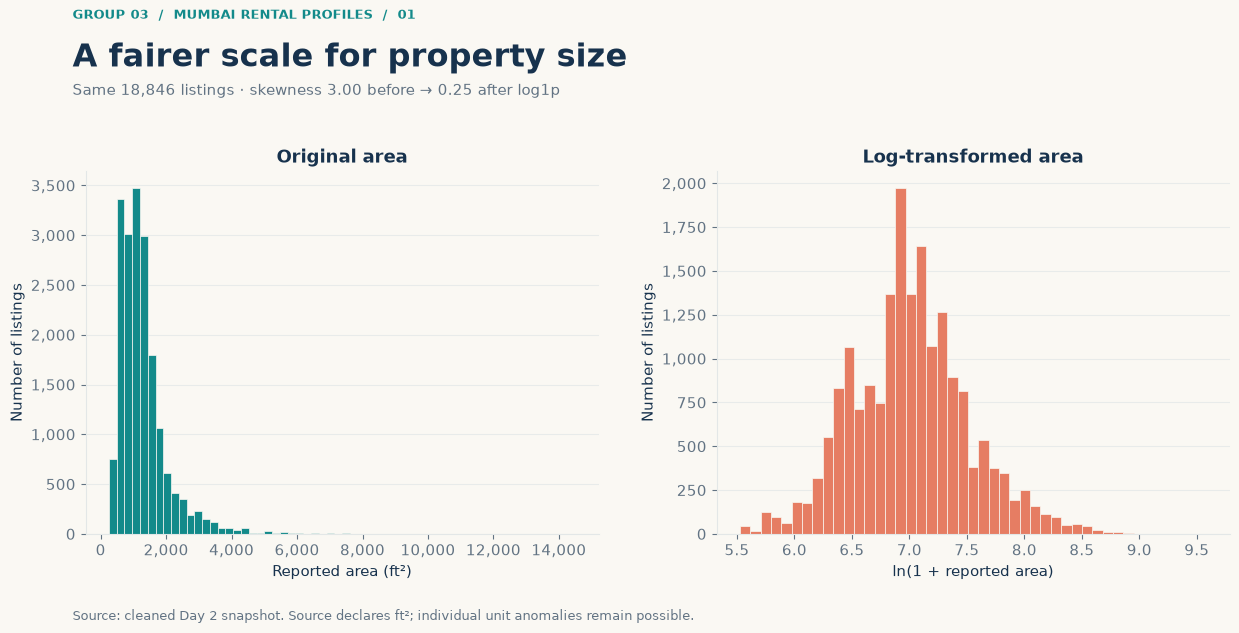

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
fig.subplots_adjust(left=0.08, right=0.96, bottom=0.17, top=0.72, wspace=0.23)
area = X_cluster["Area_num"]
axes[0].hist(area, bins=60, color=TEAL, edgecolor=PAPER, linewidth=0.5)
axes[1].hist(np.log1p(area), bins=45, color=CORAL, edgecolor=PAPER, linewidth=0.5)
for ax in axes:
    ax.set_ylabel("Number of listings")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
axes[0].set(xlabel="Reported area (ft²)", title="Original area")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
axes[1].set(xlabel="ln(1 + reported area)", title="Log-transformed area")
heading(fig, "01", "A fairer scale for property size",
        f"Same {len(area):,} listings · skewness {area.skew():.2f} before → {np.log1p(area).skew():.2f} after log1p",
        "Source: cleaned Day 2 snapshot. Source declares ft²; individual unit anomalies remain possible.")
save_figure(fig, "01_area_transformation")

### Figure 2 — PCA: Explained Variance

This figure shows the proportion of variance explained by each principal component (PC) and the cumulative variance explained by the components. PCA transforms the three original features, log-transformed property area, number of bedrooms, and number of bathrooms, into new axes that capture the main directions of variation in the dataset.

The first principal component (PC1) captures the largest proportion of variance, while PC2 captures the next largest proportion. Together, the first two components reportedly explain approximately **96.31% of the total variance**, allowing the dataset to be represented in two dimensions while retaining most of its variation.

**Key takeaway:** PCA helps reduce the dimensionality of the dataset while preserving most of the information represented by the variance in the original features.

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3, svd_solver="full")
pca_scores = pca.fit_transform(X_scaled)
variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)
components_for_95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)

pca_coordinates = pd.DataFrame({
    "source_row": analysis_data["source_row"].to_numpy(),
    "pca_x": pca_scores[:, 0],
    "pca_y": pca_scores[:, 1],
}, index=analysis_data.index)
assert len(pca_coordinates) == len(analysis_data)
assert np.isfinite(pca_scores).all()
np.testing.assert_allclose(variance_ratio.sum(), 1.0)

display(pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3"],
    "Explained variance (%)": 100 * variance_ratio,
    "Cumulative variance (%)": 100 * cumulative_variance,
}).round(2))
print("Components needed for at least 95% variance:", components_for_95)
print("Coordinates are kept in memory; the final dataset has not been exported.")

,Component,Explained variance (%),Cumulative variance (%)
0,PC1,90.19,90.19
1,PC2,6.12,96.31
2,PC3,3.69,100.00


Components needed for at least 95% variance: 2
Coordinates are kept in memory; the final dataset has not been exported.


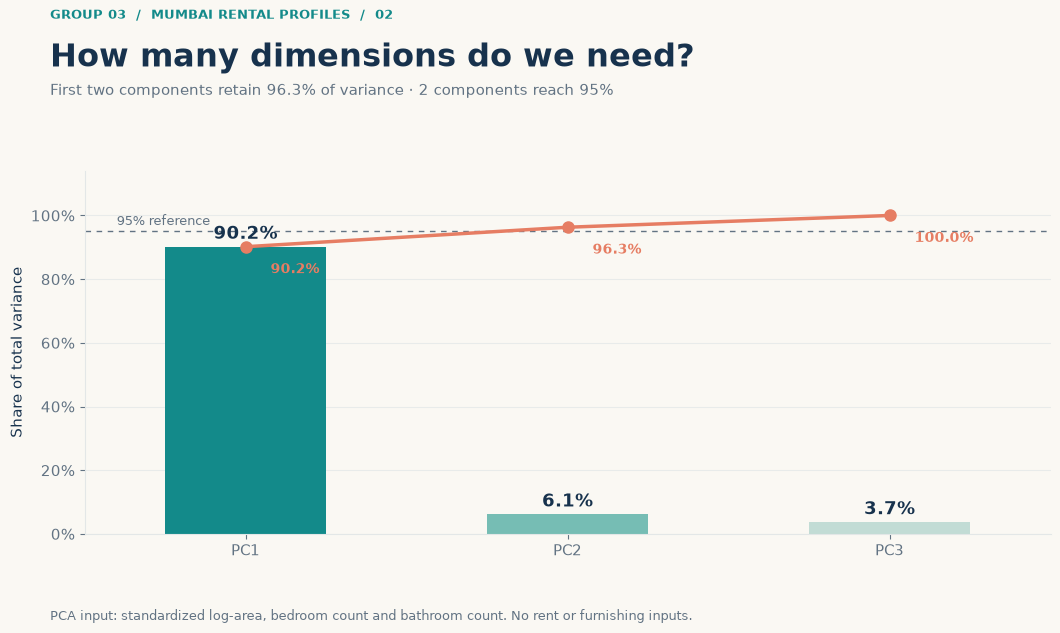

In [23]:
fig, ax = plt.subplots(figsize=(11.5, 6.6))
fig.subplots_adjust(left=0.10, right=0.94, bottom=0.17, top=0.72)
x = np.arange(1, 4)
ax.bar(x, variance_ratio, width=0.50, color=[TEAL, "#76BDB4", "#C2DCD5"], zorder=2)
ax.plot(x, cumulative_variance, color=CORAL, marker="o", markersize=8, linewidth=2.5, zorder=3)
ax.axhline(0.95, color=MUTED, linestyle=(0, (4, 4)), linewidth=1)
ax.text(0.60, 0.97, "95% reference", color=MUTED, fontsize=9)
for index, value in enumerate(variance_ratio, 1):
    ax.text(index, value + 0.025, f"{value:.1%}", ha="center", weight="bold", fontsize=13)
for index, value in enumerate(cumulative_variance, 1):
    ax.annotate(f"{value:.1%}", (index, value), xytext=(18, -19),
                textcoords="offset points", color=CORAL, fontsize=10, weight="bold")
ax.set(xlim=(0.5, 3.5), ylim=(0, 1.14), xticks=x, xticklabels=["PC1", "PC2", "PC3"],
       ylabel="Share of total variance")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y")
ax.set_axisbelow(True)
heading(fig, "02", "How many dimensions do we need?",
        f"First two components retain {cumulative_variance[1]:.1%} of variance · {components_for_95} components reach 95%",
        "PCA input: standardized log-area, bedroom count and bathroom count. No rent or furnishing inputs.")
save_figure(fig, "02_pca_explained_variance")

### Figure 3 — PCA: Interpreting the Principal Components

This figure shows the coefficients (loadings) of the original features, log-transformed property area, number of bedrooms, and number of bathrooms, for the first two principal components (PC1 and PC2).

These coefficients indicate how each feature contributes to a principal component. Features with larger absolute coefficients have a stronger influence on that component, while the sign indicates the direction of the relationship.

By examining these loadings, we can better understand the patterns captured by PCA and interpret the new axes in terms of the original property characteristics.

**Key takeaway:** PCA loadings help explain which features contribute most to each principal component, making the reduced-dimensional representation easier to interpret.

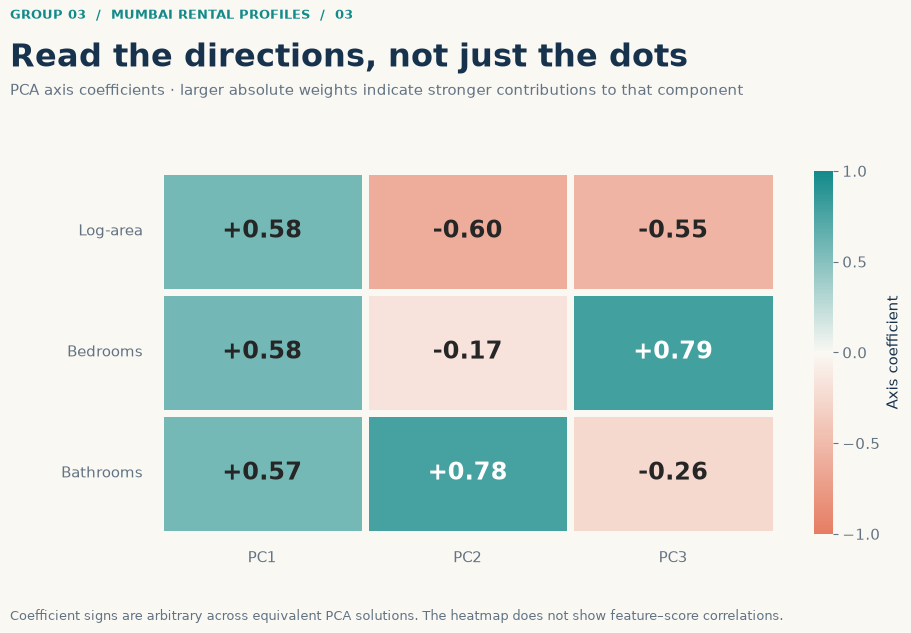

In [24]:
import seaborn as sns

axis_weights = pd.DataFrame(
    pca.components_.T,
    index=["Log-area", "Bedrooms", "Bathrooms"],
    columns=["PC1", "PC2", "PC3"],
)
fig, ax = plt.subplots(figsize=(11.5, 6.6))
fig.subplots_adjust(left=0.20, right=0.87, bottom=0.17, top=0.72)
weight_colors = LinearSegmentedColormap.from_list("axis_weights", [CORAL, PAPER, TEAL])
sns.heatmap(axis_weights, ax=ax, annot=True, fmt="+.2f", cmap=weight_colors,
            vmin=-1, vmax=1, center=0, linewidths=5, linecolor=PAPER,
            annot_kws={"size":17, "weight":"bold"},
            cbar_kws={"label":"Axis coefficient", "ticks":[-1, -0.5, 0, 0.5, 1]})
ax.tick_params(axis="both", length=0, pad=12)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
heading(fig, "03", "Read the directions, not just the dots",
        "PCA axis coefficients · larger absolute weights indicate stronger contributions to that component",
        "Coefficient signs are arbitrary across equivalent PCA solutions. The heatmap does not show feature–score correlations.")
save_figure(fig, "03_pca_axis_weights")

### Figure 4 — Visualising Physical Similarity and Rent

This figure represents the Mumbai rental listings in a two-dimensional PCA space using the first two principal components (PC1 and PC2). The left plot shows how the listings are distributed across the reduced-dimensional space, while the right plot colours the listings according to their median advertised monthly rent.

The visualisation helps us explore patterns in the dataset and investigate whether properties with similar physical characteristics tend to have similar rental prices. Areas with different colours may indicate variations in rent across the PCA space.

These plots are exploratory and do not establish that distinct clusters exist. Further analysis using clustering algorithms is required to identify and evaluate potential groups of similar properties.

**Key takeaway:** PCA provides a two-dimensional view of the rental listings, helping us explore relationships between property characteristics and rent before performing clustering.

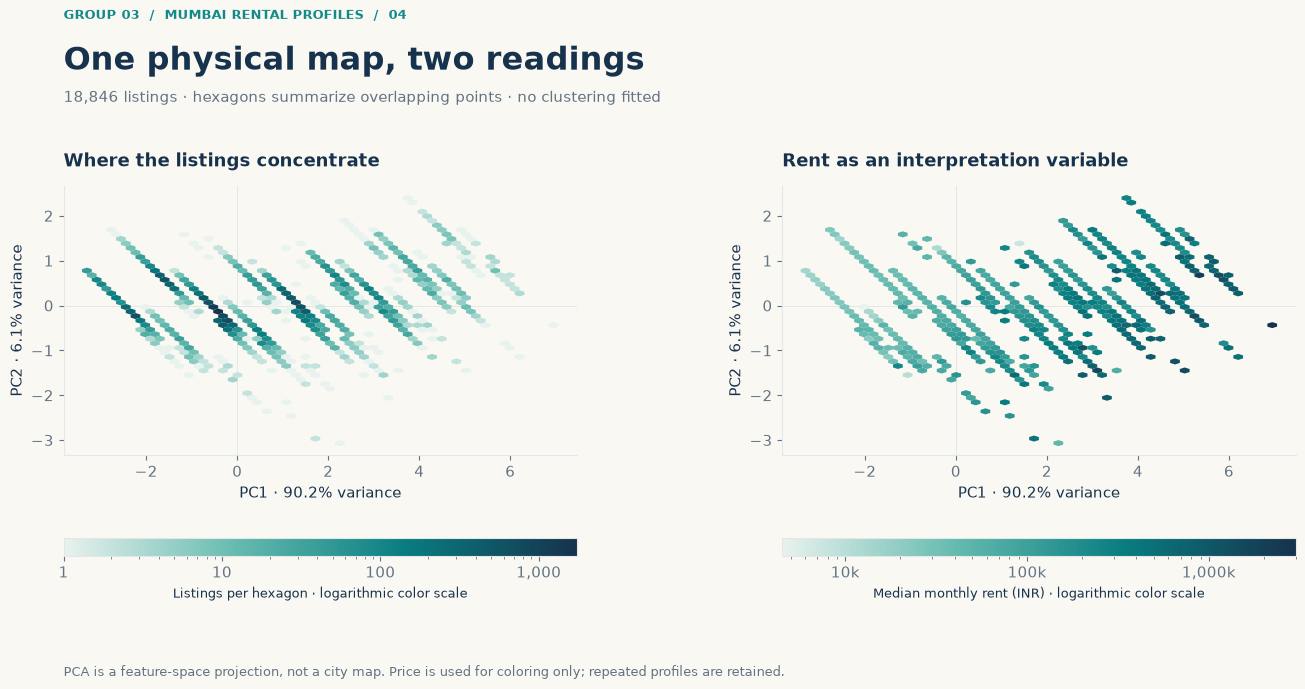

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.2))
fig.subplots_adjust(left=0.07, right=0.95, bottom=0.20, top=0.72, wspace=0.40)
x_map, y_map = pca_scores[:, 0], pca_scores[:, 1]
density = axes[0].hexbin(x_map, y_map, gridsize=48, mincnt=1,
                         cmap=map_colors, norm=LogNorm(), linewidths=0)
rent_map = axes[1].hexbin(x_map, y_map,
    C=analysis_data["Price_num"].to_numpy(), reduce_C_function=np.median,
    gridsize=48, mincnt=1, cmap=map_colors, norm=LogNorm(), linewidths=0)
axes[0].set_title("Where the listings concentrate", loc="left", pad=14)
axes[1].set_title("Rent as an interpretation variable", loc="left", pad=14)
for ax in axes:
    ax.set_xlabel(f"PC1 · {variance_ratio[0]:.1%} variance")
    ax.set_ylabel(f"PC2 · {variance_ratio[1]:.1%} variance")
    ax.axhline(0, color=GRID, linewidth=0.7, zorder=0)
    ax.axvline(0, color=GRID, linewidth=0.7, zorder=0)
bar1 = fig.colorbar(density, ax=axes[0], orientation="horizontal", pad=0.22, fraction=0.06, aspect=28)
bar1.set_label("Listings per hexagon · logarithmic color scale", fontsize=9)
bar1.ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
bar2 = fig.colorbar(rent_map, ax=axes[1], orientation="horizontal", pad=0.22, fraction=0.06, aspect=28)
bar2.set_label("Median monthly rent (INR) · logarithmic color scale", fontsize=9)
bar2.ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value/1000:,.0f}k"))
heading(fig, "04", "One physical map, two readings",
        f"{len(analysis_data):,} listings · hexagons summarize overlapping points · no clustering fitted",
        "PCA is a feature-space projection, not a city map. Price is used for coloring only; repeated profiles are retained.")
save_figure(fig, "04_pca_density_and_rent")


### Step 3 — Summary

In this step, we explored the Mumbai rental dataset through visualisations and Principal Component Analysis (PCA).

- **Log transformation:** Examined how transforming property area reduces the influence of very large values and helps us understand the feature's distribution.
- **Explained variance:** Evaluated how much variation each principal component captures. The first two components reportedly explain approximately 96.31% of the total variance.
- **PCA coefficients:** Investigated how property area, bedrooms, and bathrooms contribute to the principal components.
- **Visual exploration:** Represented the listings in two dimensions and explored how rental prices vary across the PCA space.

**Key takeaway:** PCA provides a lower-dimensional representation that preserves most of the variation in the prepared features. These visualisations help us understand the dataset before clustering, but they do not establish that distinct clusters exist.

